# What average churn hides

This notebook produces every number and chart in the write-up ([README.md](README.md)).

The data is made up. `make_data.py` generates it and says what was planted. The measures live in `churn.py`, so the cells here stay short: each one calls a function and shows what comes back.

In [1]:
import pandas as pd
from IPython.display import Image

import churn as c
import charts

pd.options.display.float_format = "{:.4f}".format
df = c.load("data/customers.csv")
f = c.facts(df)          # every number quoted in the write-up
first, last = c.window(df)
early = list(range(first, first + 6))     # Jan to Jun 2024
late = list(range(last - 5, last + 1))    # Jul to Dec 2025
print(f"{len(df):,} customers, {c.label(first)} to {c.label(last)}")
df[["customer_id", "segment", "signup_month", "offer", "monthly_price", "churn_month"]].head(8)

20,575 customers, 2024-01 to 2025-12


,customer_id,segment,signup_month,offer,monthly_price,churn_month
0,C00001,Self-serve,2024-01,,39.0000,
1,C00002,Sales-led,2025-12,,310.0000,
2,C00003,Sales-led,2020-02,,200.0000,
3,C00004,Self-serve,2025-08,Half price for 3 months,39.0000,
4,C00005,Sales-led,2025-10,,280.0000,
5,C00006,Sales-led,2025-10,,590.0000,
6,C00007,Self-serve,2025-12,Half price for 3 months,39.0000,
7,C00008,Sales-led,2024-12,,320.0000,


## 1. The number on the dashboard

Monthly churn: of the customers paying at the start of a month, the share who left during it. A customer who signs up in March is first counted in April.

In [2]:
overall = c.monthly(df)
print(f"First six months: {c.pooled(overall, early):.2%}")
print(f"Last six months:  {c.pooled(overall, late):.2%}")
print(f"Lowest month:     {overall.loc[overall['rate'].idxmin(), 'month']} at {overall['rate'].min():.2%}")
overall[["month", "active", "churned", "rate"]].iloc[::3]

First six months: 3.23%
Last six months:  3.22%
Lowest month:     2025-03 at 2.24%


,month,active,churned,rate
0,2024-01,5800,184,0.0317
3,2024-04,6285,205,0.0326
6,2024-07,6891,218,0.0316
9,2024-10,7528,236,0.0313
12,2025-01,8292,247,0.0298
15,2025-04,9764,261,0.0267
18,2025-07,11261,347,0.0308
21,2025-10,12661,417,0.0329


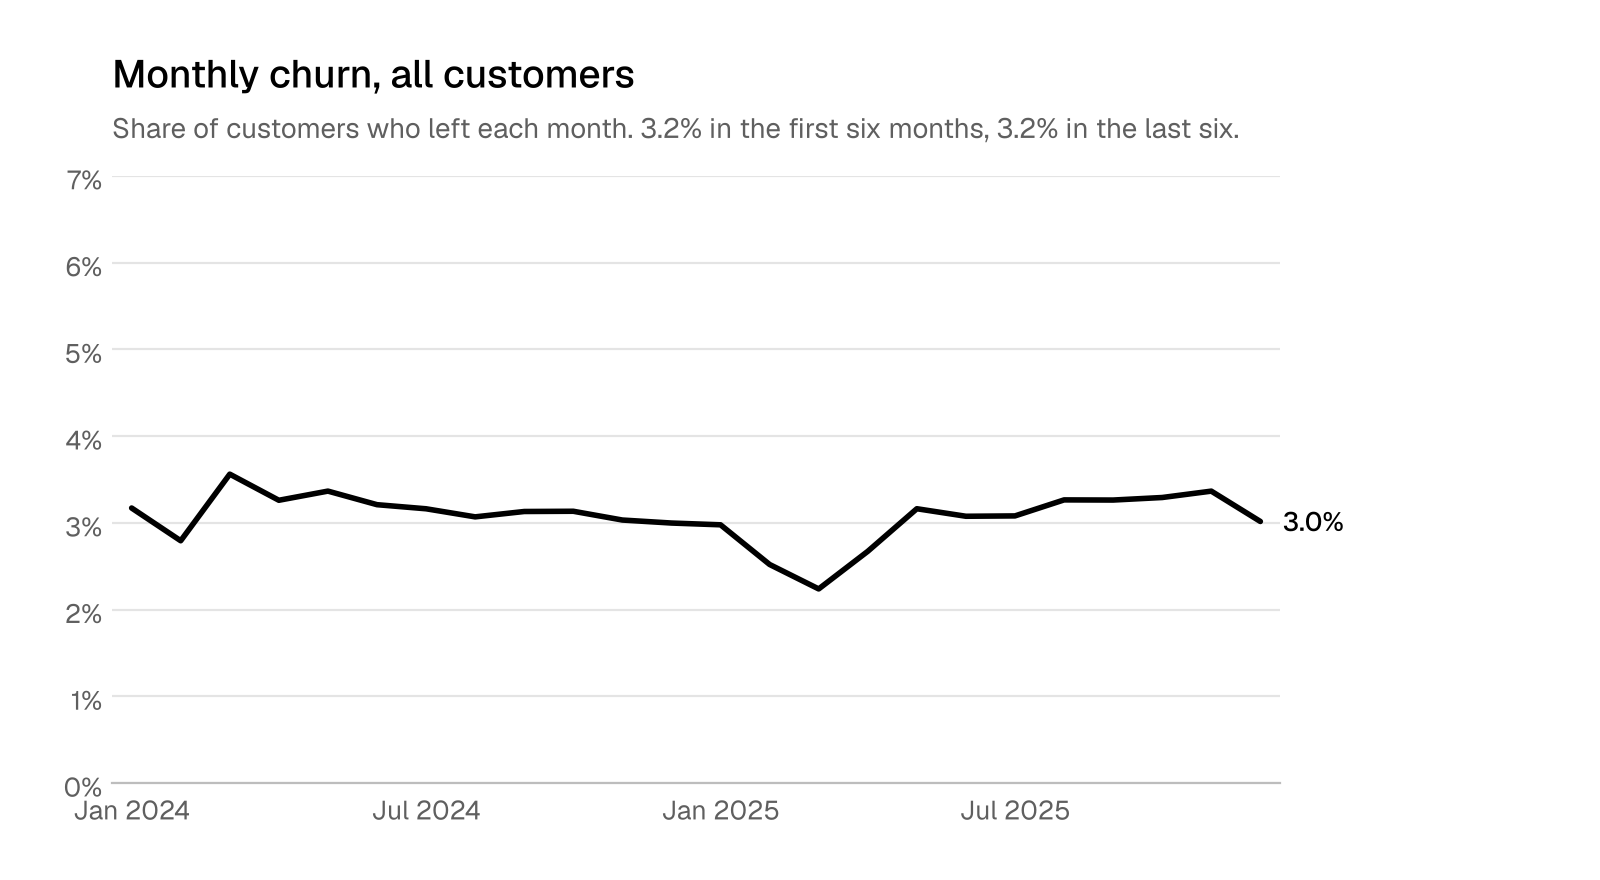

In [3]:
Image(charts.chart_overall(df, f), width=760)

## 2. Split it once

Same measure, by how the customer buys.

In [4]:
seg = c.monthly(df, "segment")
table = pd.DataFrame({"first six months": c.pooled(seg, early, "segment"), "last six months": c.pooled(seg, late, "segment")})
table.loc["All customers"] = [c.pooled(overall, early), c.pooled(overall, late)]
table.style.format("{:.2%}")

,first six months,last six months
segment,,
Sales-led,2.41%,1.09%
Self-serve,3.75%,5.53%
All customers,3.23%,3.22%


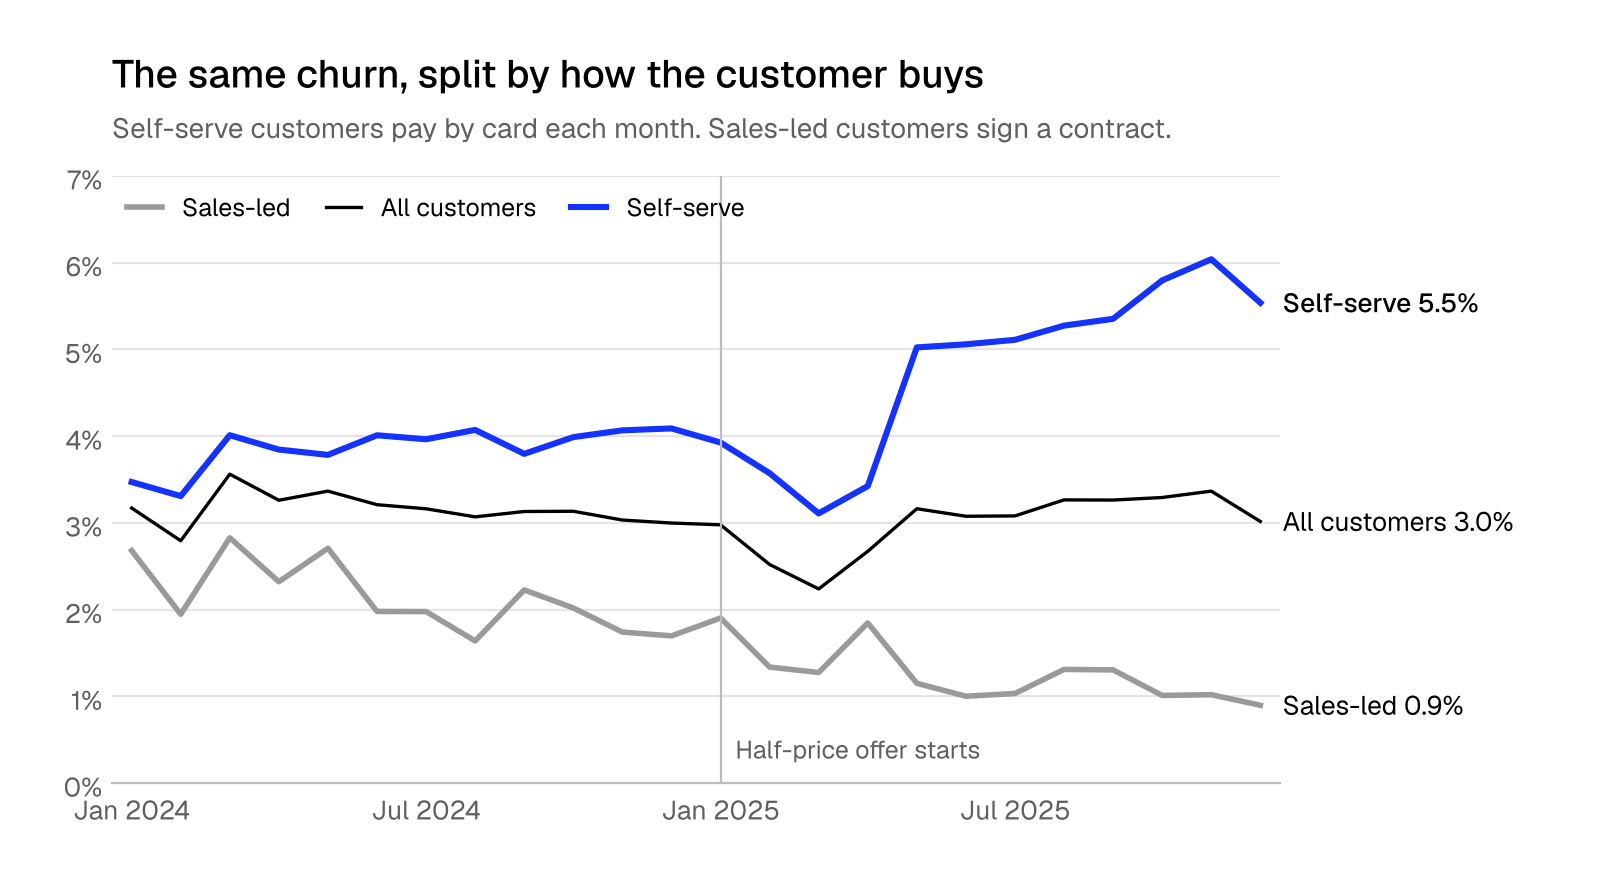

In [5]:
Image(charts.chart_segments(df, f), width=760)

## 3. Why the total did not move

The total is a weighted average of the two segments. Its change between two periods splits into each segment's own rate changing and the mix of customers changing. `decompose` uses average weights so the pieces add up exactly.

In [6]:
parts, a0, a1 = c.decompose(df, early, late)
check = parts["rate_part"].sum() + parts["mix_part"].sum()
print(f"Change in the total: {(a1 - a0) * 100:+.3f} points.  Sum of the pieces: {check * 100:+.3f} points.")
parts.style.format({"share_early": "{:.1%}", "share_late": "{:.1%}", "rate_early": "{:.2%}", "rate_late": "{:.2%}", "rate_part": "{:+.4f}", "mix_part": "{:+.4f}"})

Change in the total: -0.017 points.  Sum of the pieces: -0.017 points.


,share_early,share_late,rate_early,rate_late,rate_part,mix_part
segment,,,,,,
Sales-led,38.4%,52.1%,2.41%,1.09%,-0.0060,-0.0020
Self-serve,61.6%,47.9%,3.75%,5.53%,+0.0097,-0.0019


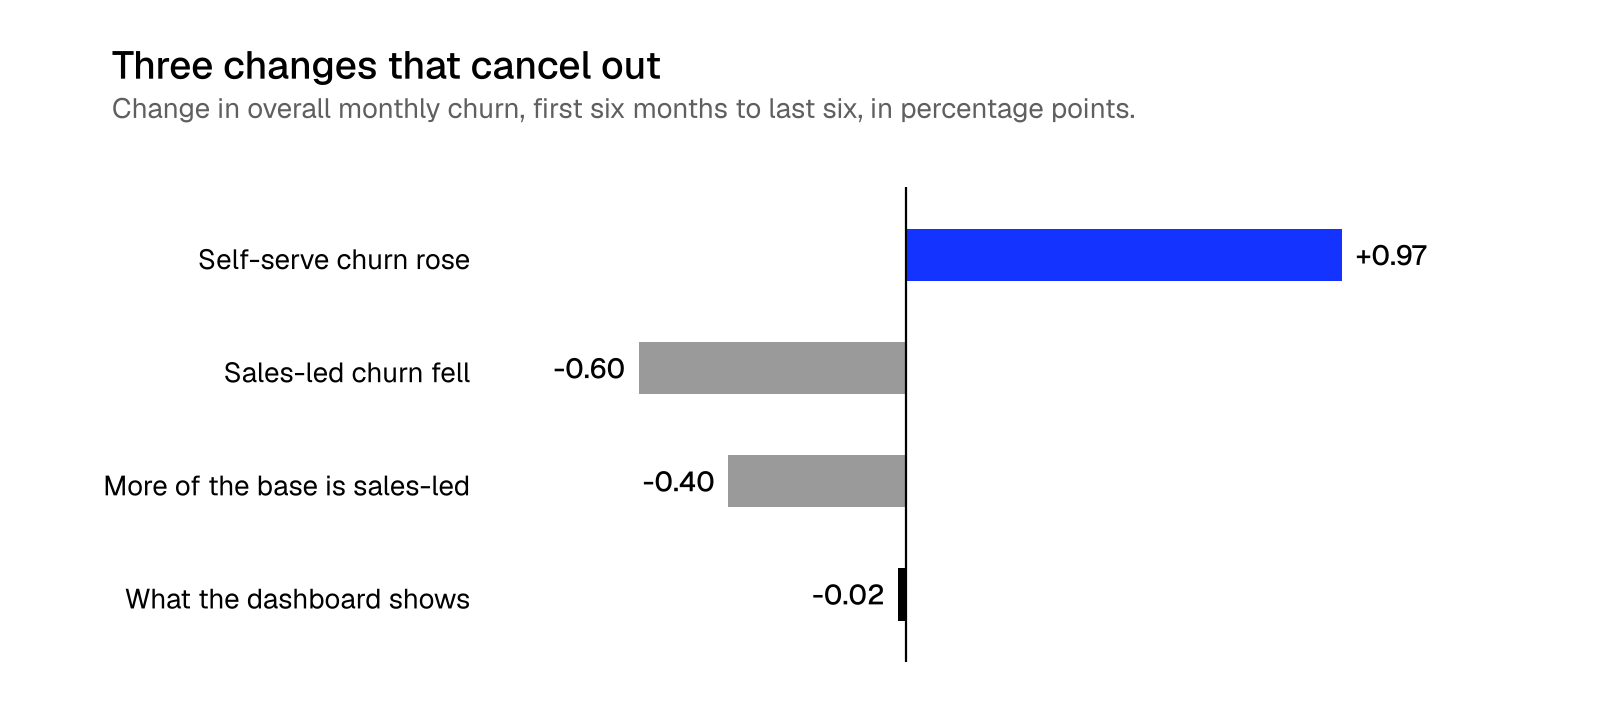

In [7]:
Image(charts.chart_parts(df, f), width=760)

## 4. Follow the signups, not the month

Three groups of self-serve customers: signed up in 2024, signed up in 2025 at full price, and signed up in 2025 on the half-price offer. Each curve only uses customers who could be followed for the full nine months.

In [8]:
groups = charts.self_serve_groups(df)
names = {"before": "Signed up in 2024", "full": "2025, full price", "offer": "2025, on the offer"}
curves = {}
for key, name in names.items():
    r, n = c.retention(groups[key], 9)
    curves[f"{name} (n={n:,})"] = r
pd.DataFrame(curves).rename_axis("months since signup").style.format("{:.1%}")

,"Signed up in 2024 (n=2,683)","2025, full price (n=272)","2025, on the offer (n=921)"
months since signup,,,
0,100.0%,100.0%,100.0%
1,93.2%,94.5%,98.3%
2,86.9%,90.8%,97.2%
3,80.5%,85.7%,95.8%
4,77.0%,84.2%,60.6%
5,74.2%,82.4%,48.2%
6,71.2%,77.6%,43.1%
7,67.9%,75.7%,40.1%
8,65.3%,73.2%,36.3%


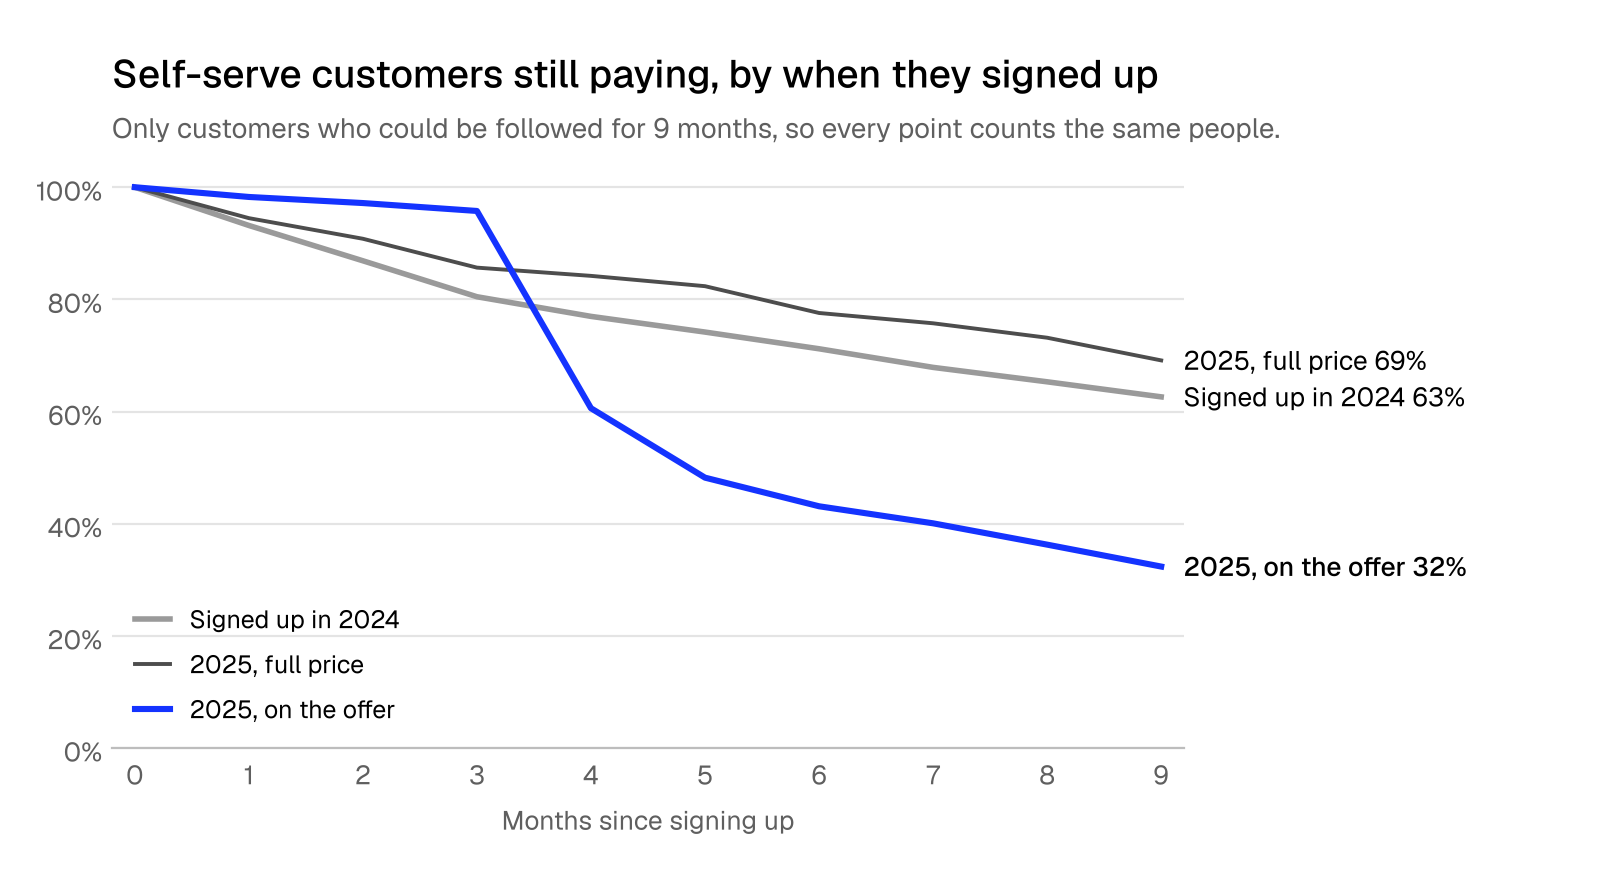

In [9]:
Image(charts.chart_cohorts(df, f), width=760)

## 5. When they leave

Of the customers who reached each month of their subscription, the share who left in it.

In [10]:
a = c.hazard_by_tenure(groups["before"], 8).set_index("tenure")
b = c.hazard_by_tenure(groups["offer"], 8).set_index("tenure")
pd.DataFrame({"2024 signups at risk": a["at_risk"], "2024 signups left": a["rate"], "offer at risk": b["at_risk"], "offer left": b["rate"]}).style.format({"2024 signups left": "{:.1%}", "offer left": "{:.1%}"})

,2024 signups at risk,2024 signups left,offer at risk,offer left
tenure,,,,
1,2683,6.8%,3553,1.2%
2,2500,6.8%,3183,1.4%
3,2331,7.4%,2819,1.6%
4,2159,4.4%,2429,34.8%
5,2065,3.6%,1382,19.0%
6,1990,4.0%,943,10.0%
7,1910,4.7%,726,7.7%
8,1821,3.8%,513,9.7%


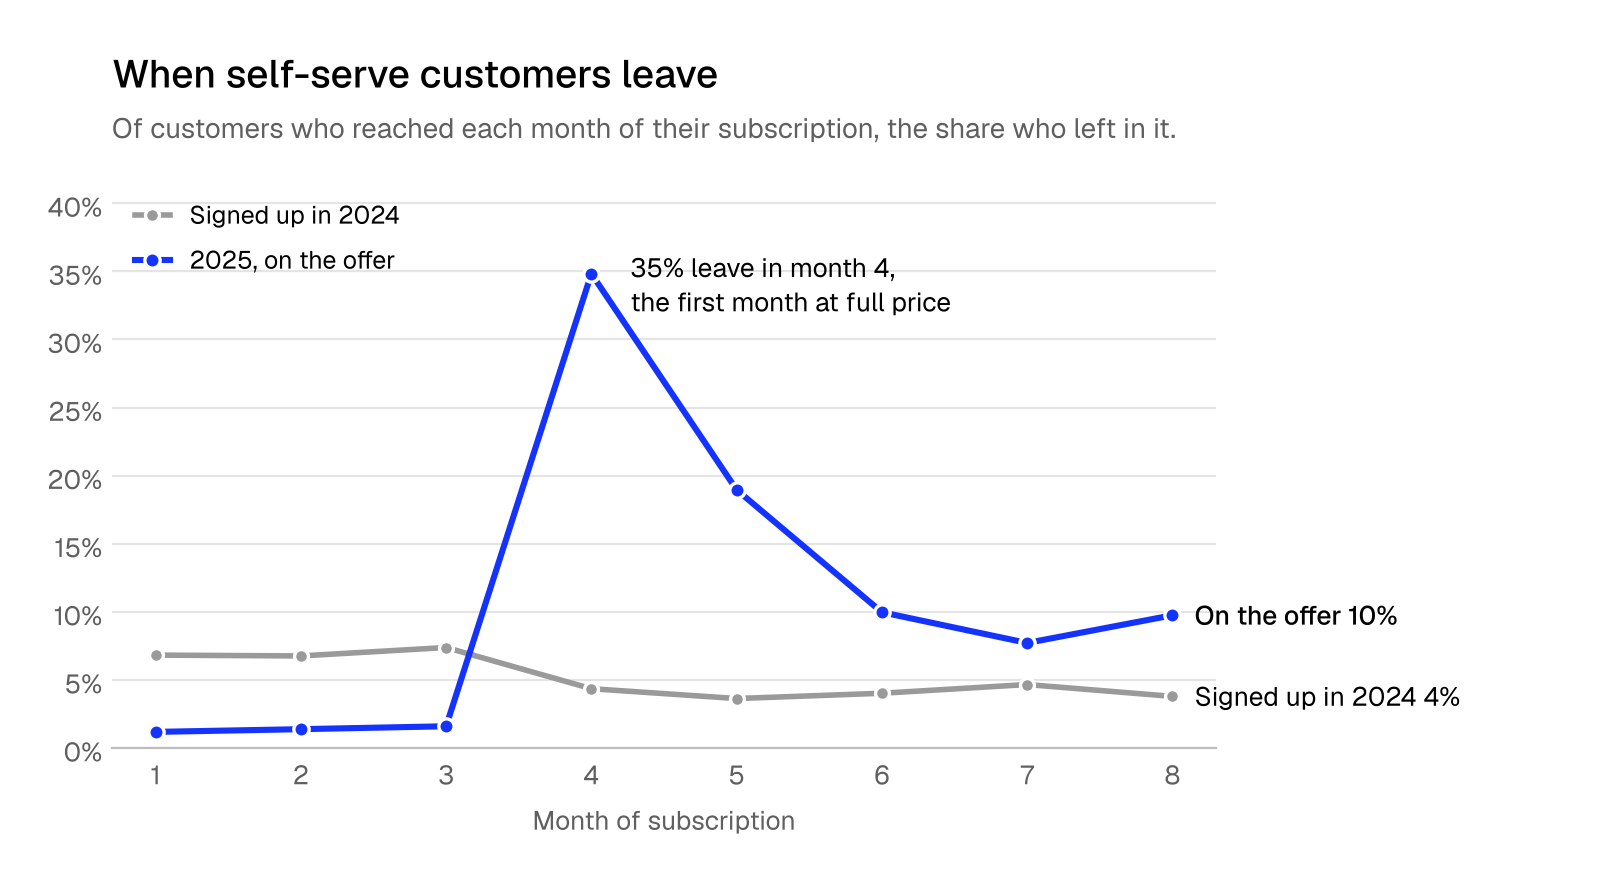

In [11]:
Image(charts.chart_hazard(df, f), width=760)

## 6. The good spring was the offer too

In the first months of the offer, new customers on half price swell the self-serve base and almost none of them leave yet. The table shows how much of the self-serve base was in its first three months, next to the self-serve churn rate.

In [12]:
ss = df[df["segment"] == "Self-serve"]
rows = []
for m in range(first + 9, last + 1):
    at_start = ss[(ss["signup"] < m) & (ss["left"].isna() | (ss["left"] >= m))]
    new = (m - at_start["signup"] <= 3).mean()
    rate = (at_start["left"] == m).mean()
    rows.append({"month": c.label(m), "self-serve customers": len(at_start), "in their first 3 months": new, "self-serve churn": rate})
pd.DataFrame(rows).set_index("month").style.format({"in their first 3 months": "{:.0%}", "self-serve churn": "{:.2%}"})

,self-serve customers,in their first 3 months,self-serve churn
month,,,
2024-10,4261,14%,10.35%
2024-11,4302,14%,11.12%
2024-12,4352,14%,11.80%
2025-01,4405,14%,12.02%
2025-02,4617,17%,10.90%
2025-03,4855,20%,9.42%
2025-04,5109,23%,10.39%
2025-05,5354,22%,15.58%
2025-06,5534,22%,16.79%


## 7. A number that would have moved

Each segment's churn for the month, weighted by the customer mix of early 2024.

Last six months as reported:      3.22%
Last six months, mix held still:  3.82%


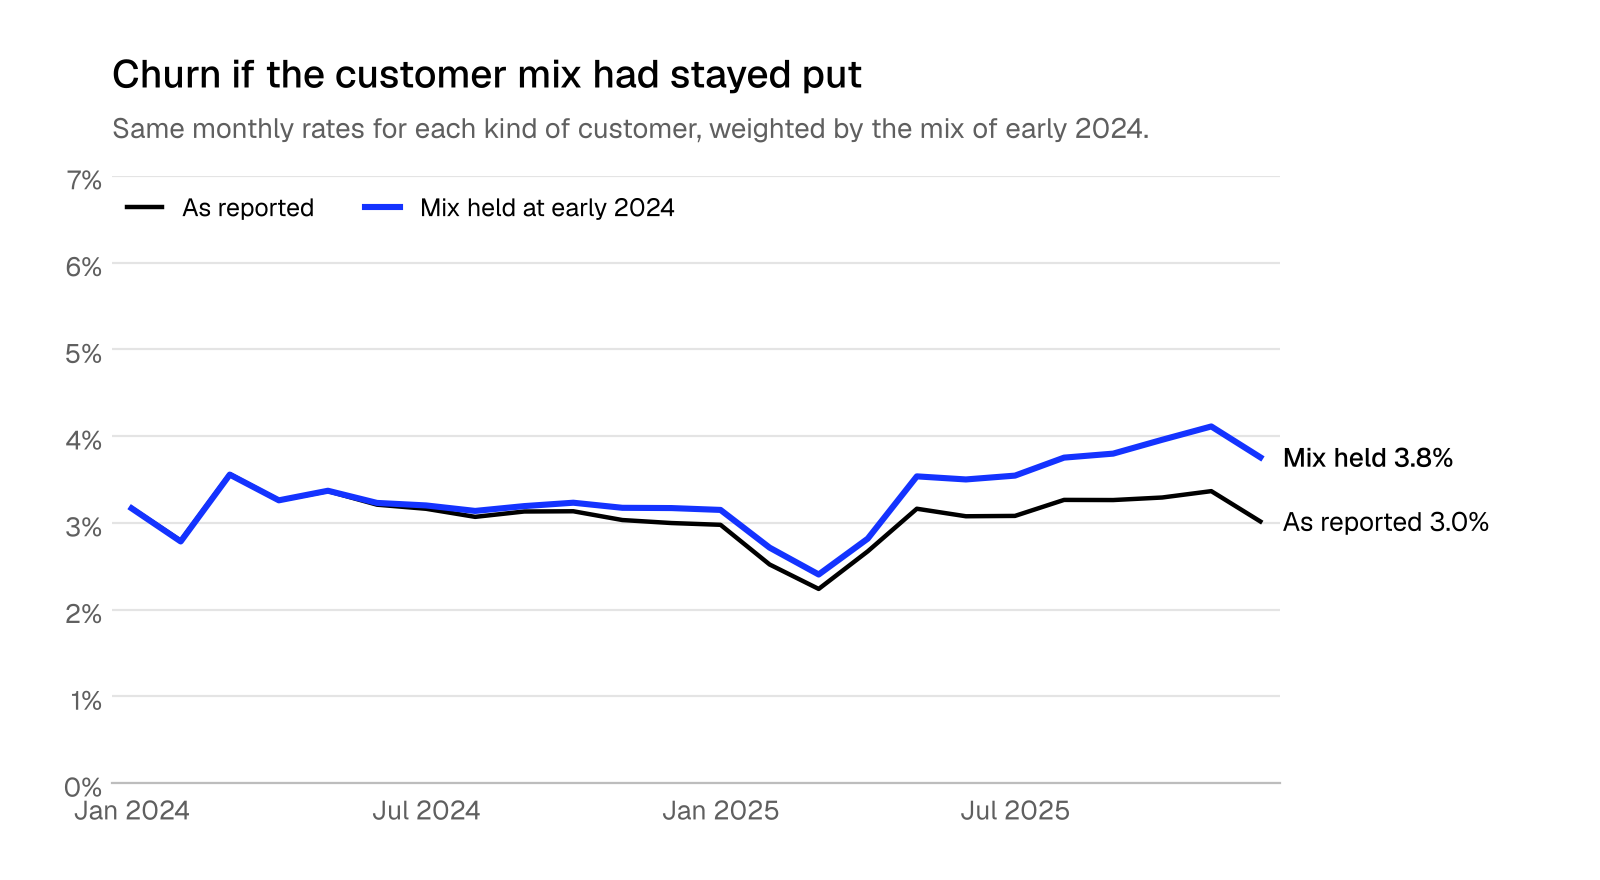

In [13]:
held = c.standardized(df, early)
print(f"Last six months as reported:      {c.pooled(overall, late):.2%}")
print(f"Last six months, mix held still:  {held[held['index'].isin(late)]['rate'].mean():.2%}")
Image(charts.chart_standardized(df, f), width=760)

## 8. Is this actually bad?

Revenue in a signup's first nine months. A customer is billed for each month after the signup month, and leaving in a month means that month was not paid.

In [14]:
rows = []
for key, name in names.items():
    value, n = c.revenue_per_signup(groups[key], 9)
    rows.append({"group": name, "signups followed": n, "revenue per signup, 9 months": value})
print(f"A month of self-serve signups, first nine months: 2024 ${f['cohort_rev_before']:,.0f}, 2025 ${f['cohort_rev_after']:,.0f}")
print(f"Self-serve share of customers at the end: {f['self_share_late']:.0%}.  Share of monthly revenue: {f['self_revenue_share']:.0%}")
pd.DataFrame(rows).set_index("group").style.format({"revenue per signup, 9 months": "${:.0f}"})

A month of self-serve signups, first nine months: 2024 $59,176, 2025 $78,839
Self-serve share of customers at the end: 48%.  Share of monthly revenue: 7%


,signups followed,"revenue per signup, 9 months"
group,,
Signed up in 2024,2683,$265
"2025, full price",272,$286
"2025, on the offer",921,$158


## The same summary for any file

`python churn.py your_customers.csv` prints this for a file of your own.

In [15]:
print(c.summary(df))

20,575 customers, 2024-01 to 2025-12
Comparing the first 6 months with the last 6

                            early     late  share early  share late
Sales-led                   2.41%    1.09%          38%         52%
Self-serve                  3.75%    5.53%          62%         48%
All customers               3.23%    3.22%

Change in the overall rate: -0.02 points, made up of
  Sales-led churn changing: -0.60
  Self-serve churn changing: +0.97
  the mix of customers changing: -0.40
Overall rate in the late period if the mix had not changed: 3.82%
